# 04. Exploratory Inspection: Raw Liver Disease Dataset

This notebook performs exploratory data inspection and analysis on the raw Indian Liver Patient Dataset (ILPD) located at:
`datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv`

**Constraints & Scope**:
- Exploratory inspection and exploratory data analysis (EDA) only.
- Raw CSV is treated as read-only and is not altered, overwritten, or modified.
- No data cleaning, imputation, transformation, or feature engineering is implemented here.
- No machine-learning models or pipelines are trained.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')

# Path to the raw Liver Disease dataset
data_path = 'datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'
print(f"Libraries imported. Dataset path set to: {data_path}")

Libraries imported. Dataset path set to: datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv


## 1. Dataset Loading and Initial Inspection
The raw data file does not contain a header row. We load the dataset using `header=None` and assign the standard 11 feature names specified in the UCI ILPD documentation without altering the underlying raw file.

In [2]:
expected_cols = [
    'Age',
    'Gender',
    'Total_Bilirubin',
    'Direct_Bilirubin',
    'Alkphos',
    'Sgpt',
    'Sgot',
    'Total_Proteins',
    'Albumin',
    'A_G_Ratio',
    'Selector'
]

df_raw = pd.read_csv(data_path, header=None, names=expected_cols)
print(f"Dataset successfully loaded from: {data_path}")
print("=== DATASET SHAPE ===")
print(f"Rows: {df_raw.shape[0]}, Columns: {df_raw.shape[1]}")

print("\n=== FIRST 10 ROWS ===")
print(df_raw.head(10).to_string())

print("\n=== LAST 5 ROWS ===")
print(df_raw.tail(5).to_string())

Dataset successfully loaded from: datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv
=== DATASET SHAPE ===
Rows: 583, Columns: 11

=== FIRST 10 ROWS ===
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkphos  Sgpt  Sgot  Total_Proteins  Albumin  A_G_Ratio  Selector
0   65  Female              0.7               0.1      187    16    18             6.8      3.3       0.90         1
1   62    Male             10.9               5.5      699    64   100             7.5      3.2       0.74         1
2   62    Male              7.3               4.1      490    60    68             7.0      3.3       0.89         1
3   58    Male              1.0               0.4      182    14    20             6.8      3.4       1.00         1
4   72    Male              3.9               2.0      195    27    59             7.3      2.4       0.40         1
5   46    Male              1.8               0.7      208    19    14             7.6      4.4       1.30         1
6   26  Female      

## 2. Column Structure & Feature Descriptions

The dataset consists of 11 columns (10 input features and 1 target variable):

1. **`Age`**: Age of the patient in years (discrete numerical, range: 4 to 90).
2. **`Gender`**: Biological sex of the patient (nominal categorical: `Male` or `Female`).
3. **`Total_Bilirubin`**: Total bilirubin level in mg/dL (continuous numerical).
4. **`Direct_Bilirubin`**: Conjugated (direct) bilirubin level in mg/dL (continuous numerical).
5. **`Alkphos`**: Alkaline Phosphatase enzyme level in U/L (continuous numerical).
6. **`Sgpt`**: Alanine Aminotransferase (ALT / SGPT) enzyme level in U/L (continuous numerical).
7. **`Sgot`**: Aspartate Aminotransferase (AST / SGOT) enzyme level in U/L (continuous numerical).
8. **`Total_Proteins`**: Total serum protein in g/dL (continuous numerical).
9. **`Albumin`**: Serum albumin protein in g/dL (continuous numerical).
10. **`A_G_Ratio`**: Ratio of Albumin to Globulin (continuous numerical).
11. **`Selector`**: Health status diagnosis (**Target variable**):
    - `1`: Liver disease patient (case)
    - `2`: Non-liver disease individual (control)

In [3]:
print("=== COLUMN STRUCTURE ===")
print(f"Total columns: {len(df_raw.columns)}")
print(f"Columns list: {list(df_raw.columns)}")
print(f"Identified Target Column: 'Selector'")

=== COLUMN STRUCTURE ===
Total columns: 11
Columns list: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio', 'Selector']
Identified Target Column: 'Selector'


## 3. Data Types and Feature Classification
Inspect inferred pandas data types and classify columns into numerical and categorical categories.

In [4]:
print("=== PANDAS DATA TYPES ===")
print(df_raw.dtypes)

cat_cols = df_raw.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = df_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nCategorical features ({len(cat_cols)}): {cat_cols}")
print(f"Numerical features ({len(num_cols)}): {num_cols}")

=== PANDAS DATA TYPES ===
Age                   int64
Gender               object
Total_Bilirubin     float64
Direct_Bilirubin    float64
Alkphos               int64
Sgpt                  int64
Sgot                  int64
Total_Proteins      float64
Albumin             float64
A_G_Ratio           float64
Selector              int64
dtype: object

Categorical features (1): ['Gender']
Numerical features (10): ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio', 'Selector']


## 4. Missing Values Audit
Check for standard pandas `NA` / `NaN` values, compute missing percentages, and audit for empty or whitespace-only strings.

In [5]:
print("=== MISSING VALUE AUDIT (NA / NaN) ===")
na_counts = df_raw.isna().sum()
na_pct = (na_counts / len(df_raw)) * 100
missing_df = pd.DataFrame({
    'Missing Count': na_counts,
    'Percentage (%)': na_pct.round(2)
})
print(missing_df)

cols_with_missing = missing_df[missing_df['Missing Count'] > 0]
print(f"\nColumns containing missing values:")
for col, row in cols_with_missing.iterrows():
    print(f"- {col}: {int(row['Missing Count'])} missing values ({row['Percentage (%)']}%)")

print("\n=== EMPTY STRING CHECK ===")
empty_strings = (df_raw.astype(str).apply(lambda col: col.str.strip()) == '').sum()
print("Empty strings count per column:")
print(empty_strings)

=== MISSING VALUE AUDIT (NA / NaN) ===
                  Missing Count  Percentage (%)
Age                           0            0.00
Gender                        0            0.00
Total_Bilirubin               0            0.00
Direct_Bilirubin              0            0.00
Alkphos                       0            0.00
Sgpt                          0            0.00
Sgot                          0            0.00
Total_Proteins                0            0.00
Albumin                       0            0.00
A_G_Ratio                     4            0.69
Selector                      0            0.00

Columns containing missing values:
- A_G_Ratio: 4 missing values (0.69%)

=== EMPTY STRING CHECK ===
Empty strings count per column:
Age                 0
Gender              0
Total_Bilirubin     0
Direct_Bilirubin    0
Alkphos             0
Sgpt                0
Sgot                0
Total_Proteins      0
Albumin             0
A_G_Ratio           0
Selector            0
dtype: in

## 5. Duplicate Records Analysis
Examine whether the raw dataset contains exact duplicate rows.
*Note: In accordance with inspection rules, duplicate rows are counted and reported, but are not removed.*

In [6]:
print("=== DUPLICATE RECORDS ANALYSIS ===")
dup_mask = df_raw.duplicated(keep=False)
dup_count = df_raw.duplicated().sum()
dup_pct = (dup_count / len(df_raw)) * 100

print(f"Total duplicate rows: {dup_count} ({dup_pct:.2f}% of dataset)")
print(f"Total rows involved in duplication (original + copies): {dup_mask.sum()}")

print("\nSample duplicated rows:")
print(df_raw[dup_mask].sort_values(by=['Age', 'Total_Bilirubin', 'Alkphos']).head(10).to_string())

=== DUPLICATE RECORDS ANALYSIS ===
Total duplicate rows: 13 (2.23% of dataset)
Total rows involved in duplication (original + copies): 26

Sample duplicated rows:
     Age Gender  Total_Bilirubin  Direct_Bilirubin  Alkphos  Sgpt  Sgot  Total_Proteins  Albumin  A_G_Ratio  Selector
137   18   Male              0.8               0.2      282    72   140             5.5      2.5        0.8         1
138   18   Male              0.8               0.2      282    72   140             5.5      2.5        0.8         1
142   30   Male              1.6               0.4      332    84   139             5.6      2.7        0.9         1
143   30   Male              1.6               0.4      332    84   139             5.6      2.7        0.9         1
173   31   Male              0.6               0.1      175    48    34             6.0      3.7        1.6         1
174   31   Male              0.6               0.1      175    48    34             6.0      3.7        1.6         1
25    34   

## 6. Target Analysis (`Selector`)
Analyze class balance, unique values, and distribution for the target column `Selector`.

In [7]:
print("=== TARGET COLUMN 'Selector' ANALYSIS ===")
unique_targets = df_raw['Selector'].unique()
print(f"Unique target values: {sorted(list(unique_targets))}")

target_counts = df_raw['Selector'].value_counts().sort_index()
target_pct = (df_raw['Selector'].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({
    'Clinical Class': ['Liver Patient (1)', 'Non-Liver Control (2)'],
    'Record Count': target_counts.values,
    'Percentage (%)': target_pct.values
}, index=[1, 2])
target_summary.index.name = 'Selector'

print("\nTarget Class Distribution:")
print(target_summary.to_string())

ratio = target_counts[1] / target_counts[2]
print(f"\nClass Imbalance Ratio (Class 1 to Class 2): {ratio:.2f} : 1")

=== TARGET COLUMN 'Selector' ANALYSIS ===
Unique target values: [np.int64(1), np.int64(2)]

Target Class Distribution:
                 Clinical Class  Record Count  Percentage (%)
Selector                                                     
1             Liver Patient (1)           416           71.36
2         Non-Liver Control (2)           167           28.64

Class Imbalance Ratio (Class 1 to Class 2): 2.49 : 1


## 7. Gender Demographic Analysis
Examine the distribution and validity of values within the `Gender` categorical feature.

In [8]:
print("=== GENDER DEMOGRAPHIC ANALYSIS ===")
unique_genders = df_raw['Gender'].unique()
print(f"Unique gender values: {unique_genders}")

gender_counts = df_raw['Gender'].value_counts(dropna=False)
gender_pct = (df_raw['Gender'].value_counts(normalize=True, dropna=False) * 100).round(2)

gender_summary = pd.DataFrame({
    'Count': gender_counts,
    'Percentage (%)': gender_pct
})
print("\nGender Breakdown:")
print(gender_summary.to_string())

print("\nCross-Tabulation: Gender vs Target Selector:")
ct = pd.crosstab(df_raw['Gender'], df_raw['Selector'], margins=True)
ct.columns = ['Liver Patient (1)', 'Non-Liver (2)', 'Total']
print(ct)

=== GENDER DEMOGRAPHIC ANALYSIS ===
Unique gender values: ['Female' 'Male']

Gender Breakdown:
        Count  Percentage (%)
Gender                       
Male      441           75.64
Female    142           24.36

Cross-Tabulation: Gender vs Target Selector:
        Liver Patient (1)  Non-Liver (2)  Total
Gender                                         
Female                 92             50    142
Male                  324            117    441
All                   416            167    583


## 8. Numerical Feature Statistics
Compute descriptive statistics (count, mean, standard deviation, quartiles, median, min, max) for all numerical features.

In [9]:
print("=== DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES ===")
features_num = [c for c in num_cols if c != 'Selector']
stats = df_raw[features_num].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats['median'] = df_raw[features_num].median()
stats_ordered = stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max']]
print(stats_ordered.round(2).to_string())

=== DESCRIPTIVE STATISTICS FOR NUMERICAL FEATURES ===
                  count    mean     std   min    25%  median    75%     max
Age               583.0   44.75   16.19   4.0   33.0   45.00   58.0    90.0
Total_Bilirubin   583.0    3.30    6.21   0.4    0.8    1.00    2.6    75.0
Direct_Bilirubin  583.0    1.49    2.81   0.1    0.2    0.30    1.3    19.7
Alkphos           583.0  290.58  242.94  63.0  175.5  208.00  298.0  2110.0
Sgpt              583.0   80.71  182.62  10.0   23.0   35.00   60.5  2000.0
Sgot              583.0  109.91  288.92  10.0   25.0   42.00   87.0  4929.0
Total_Proteins    583.0    6.48    1.09   2.7    5.8    6.60    7.2     9.6
Albumin           583.0    3.14    0.80   0.9    2.6    3.10    3.8     5.5
A_G_Ratio         579.0    0.95    0.32   0.3    0.7    0.93    1.1     2.8


## 9. Physiological & Extreme Value Inspection
Inspect boundary ranges, skewness, and extreme values across each numerical feature without making premature assumptions of invalidity.

In [10]:
print("=== PHYSIOLOGICAL / DATA QUALITY INSPECTION ===")
for col in features_num:
    vmin, vmax = df_raw[col].min(), df_raw[col].max()
    vmedian = df_raw[col].median()
    iqr = df_raw[col].quantile(0.75) - df_raw[col].quantile(0.25)
    upper_threshold = df_raw[col].quantile(0.75) + 1.5 * iqr
    outliers = (df_raw[col] > upper_threshold).sum()
    print(f"Feature '{col}':")
    print(f"  Range: [{vmin:.2f}, {vmax:.2f}] | Median: {vmedian:.2f}")
    print(f"  Observations > Q3 + 1.5*IQR ({upper_threshold:.2f}): {outliers}")

=== PHYSIOLOGICAL / DATA QUALITY INSPECTION ===
Feature 'Age':
  Range: [4.00, 90.00] | Median: 45.00
  Observations > Q3 + 1.5*IQR (95.50): 0
Feature 'Total_Bilirubin':
  Range: [0.40, 75.00] | Median: 1.00
  Observations > Q3 + 1.5*IQR (5.30): 84
Feature 'Direct_Bilirubin':
  Range: [0.10, 19.70] | Median: 0.30
  Observations > Q3 + 1.5*IQR (2.95): 81
Feature 'Alkphos':
  Range: [63.00, 2110.00] | Median: 208.00
  Observations > Q3 + 1.5*IQR (481.75): 69
Feature 'Sgpt':
  Range: [10.00, 2000.00] | Median: 35.00
  Observations > Q3 + 1.5*IQR (116.75): 73
Feature 'Sgot':
  Range: [10.00, 4929.00] | Median: 42.00
  Observations > Q3 + 1.5*IQR (180.00): 66
Feature 'Total_Proteins':
  Range: [2.70, 9.60] | Median: 6.60
  Observations > Q3 + 1.5*IQR (9.30): 2
Feature 'Albumin':
  Range: [0.90, 5.50] | Median: 3.10
  Observations > Q3 + 1.5*IQR (5.60): 0
Feature 'A_G_Ratio':
  Range: [0.30, 2.80] | Median: 0.93
  Observations > Q3 + 1.5*IQR (1.70): 10


## 10. Distribution Visualizations
Plot histograms with kernel density estimates for numerical features and bar plots for target and demographic distributions.

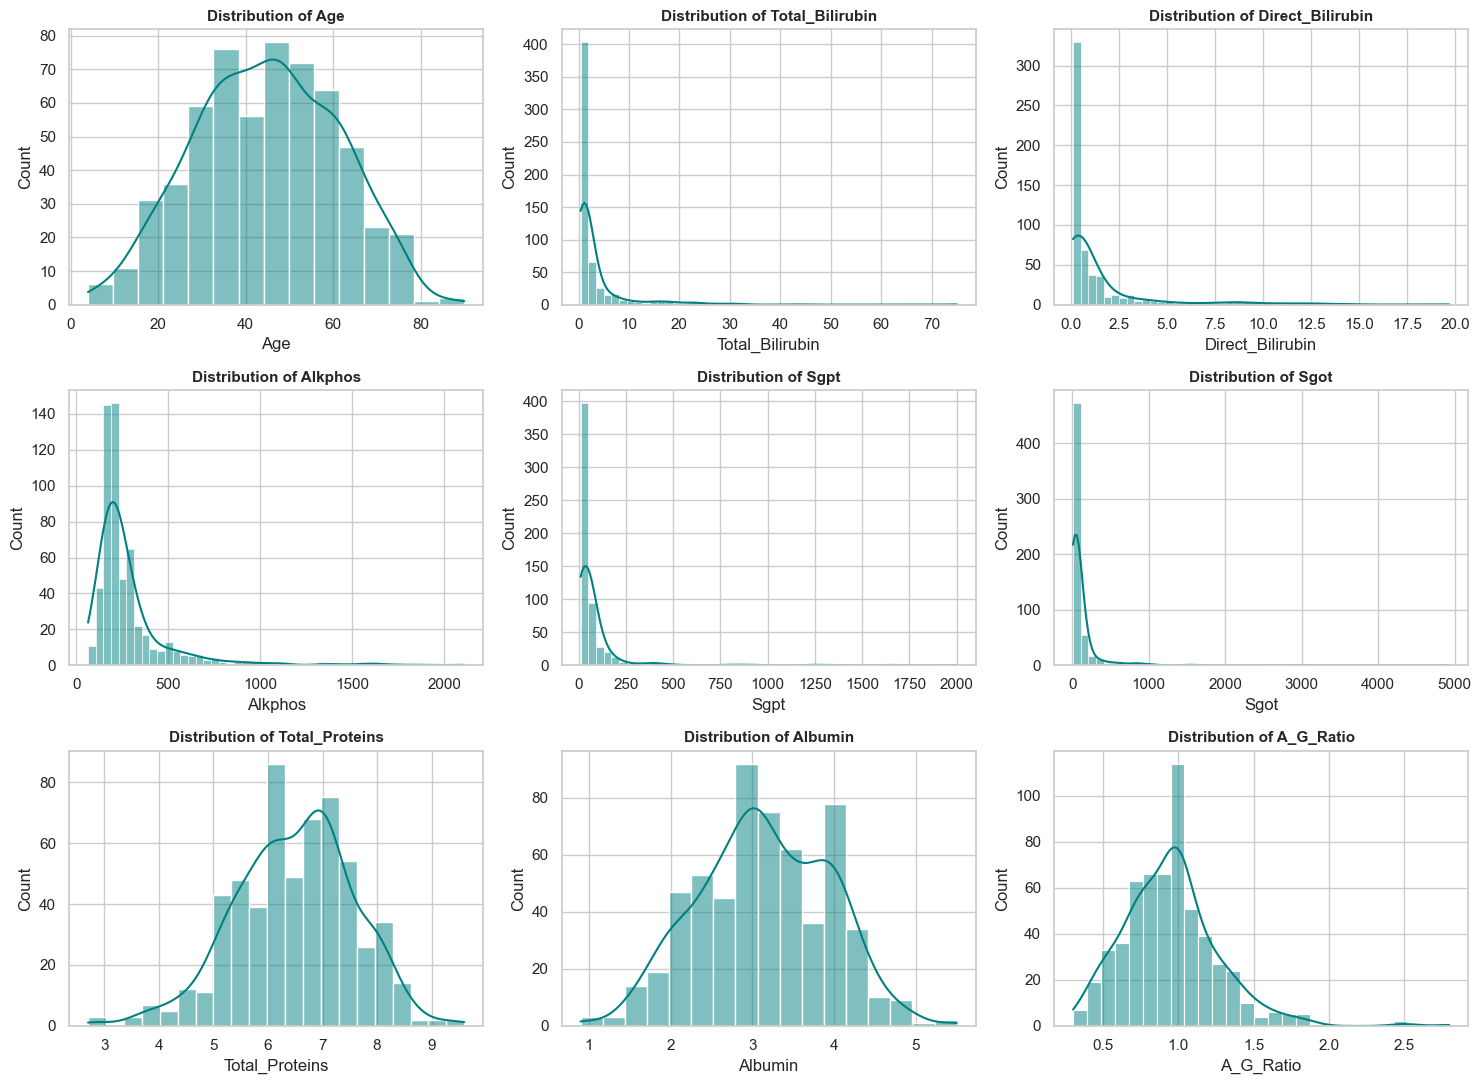

C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\1932375139.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, x='Selector', palette='Set2', ax=ax1)
C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\1932375139.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['Liver Patient (1)', 'Non-Liver (2)'])
C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\1932375139.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_raw, x='Gender', palette='Pastel1', ax=ax2)


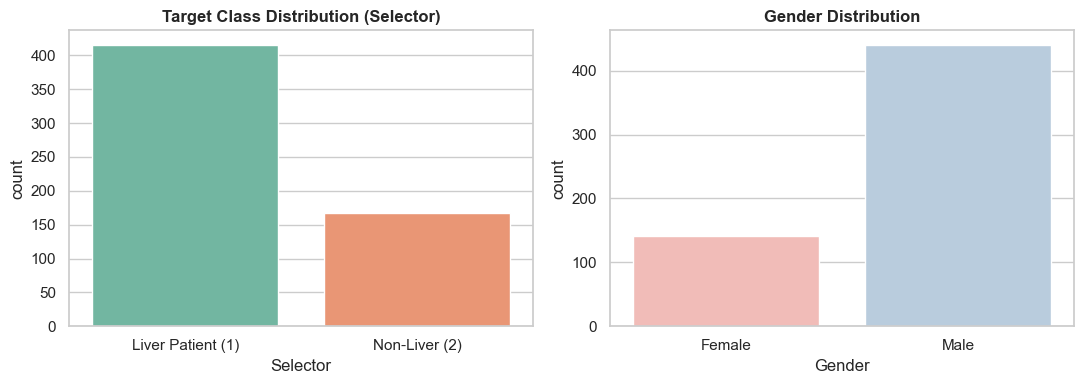

In [11]:
# Histograms for numerical features
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
features_to_plot = ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio']

for ax, feat in zip(axes.flatten(), features_to_plot):
    sns.histplot(df_raw[feat].dropna(), kde=True, ax=ax, color='teal')
    ax.set_title(f'Distribution of {feat}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

# Target class and gender counts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df_raw, x='Selector', palette='Set2', ax=ax1)
ax1.set_title('Target Class Distribution (Selector)', fontsize=12, fontweight='bold')
ax1.set_xticklabels(['Liver Patient (1)', 'Non-Liver (2)'])

sns.countplot(data=df_raw, x='Gender', palette='Pastel1', ax=ax2)
ax2.set_title('Gender Distribution', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Feature Relationships & Correlation Analysis
Compute and visualize the correlation matrix across numerical features to identify collinearity.

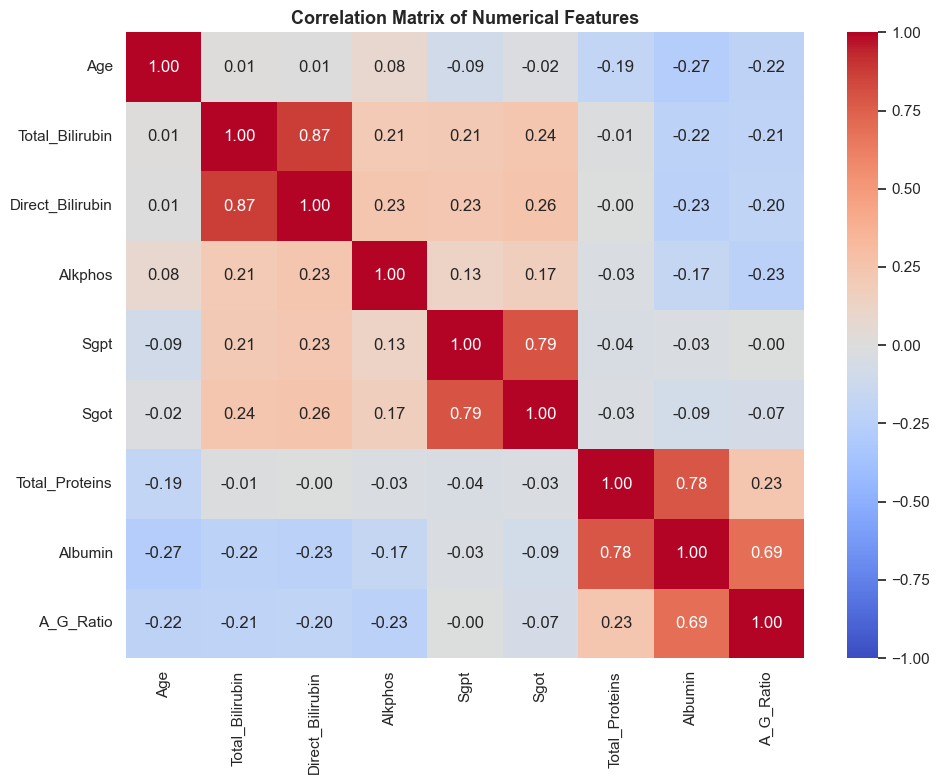

Key Pairwise Correlations (|r| >= 0.65):
- Total_Bilirubin & Direct_Bilirubin: r = 0.875
- Sgpt & Sgot: r = 0.792
- Total_Proteins & Albumin: r = 0.784
- Albumin & A_G_Ratio: r = 0.690


In [12]:
plt.figure(figsize=(10, 8))
corr_matrix = df_raw[features_num].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Key Pairwise Correlations (|r| >= 0.65):")
for i in range(len(features_num)):
    for j in range(i + 1, len(features_num)):
        r = corr_matrix.iloc[i, j]
        if abs(r) >= 0.65:
            print(f"- {features_num[i]} & {features_num[j]}: r = {r:.3f}")

## 12. Feature Comparison Across Target Classes
Compare numerical feature distributions between Liver Disease patients (`Selector=1`) and Non-Liver controls (`Selector=2`) using boxplots.

C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\2157551423.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Selector', y=feat, palette='Set2', ax=ax, showfliers=False)
C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\2157551423.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Liver Patient (1)', 'Non-Liver (2)'])
C:\Users\Debraj Mondal\AppData\Local\Temp\ipykernel_21960\2157551423.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Selector', y=feat, palette='Set2', ax=ax, showfliers=False)
C:\Users\Debraj Mondal\AppData\Local\Tem

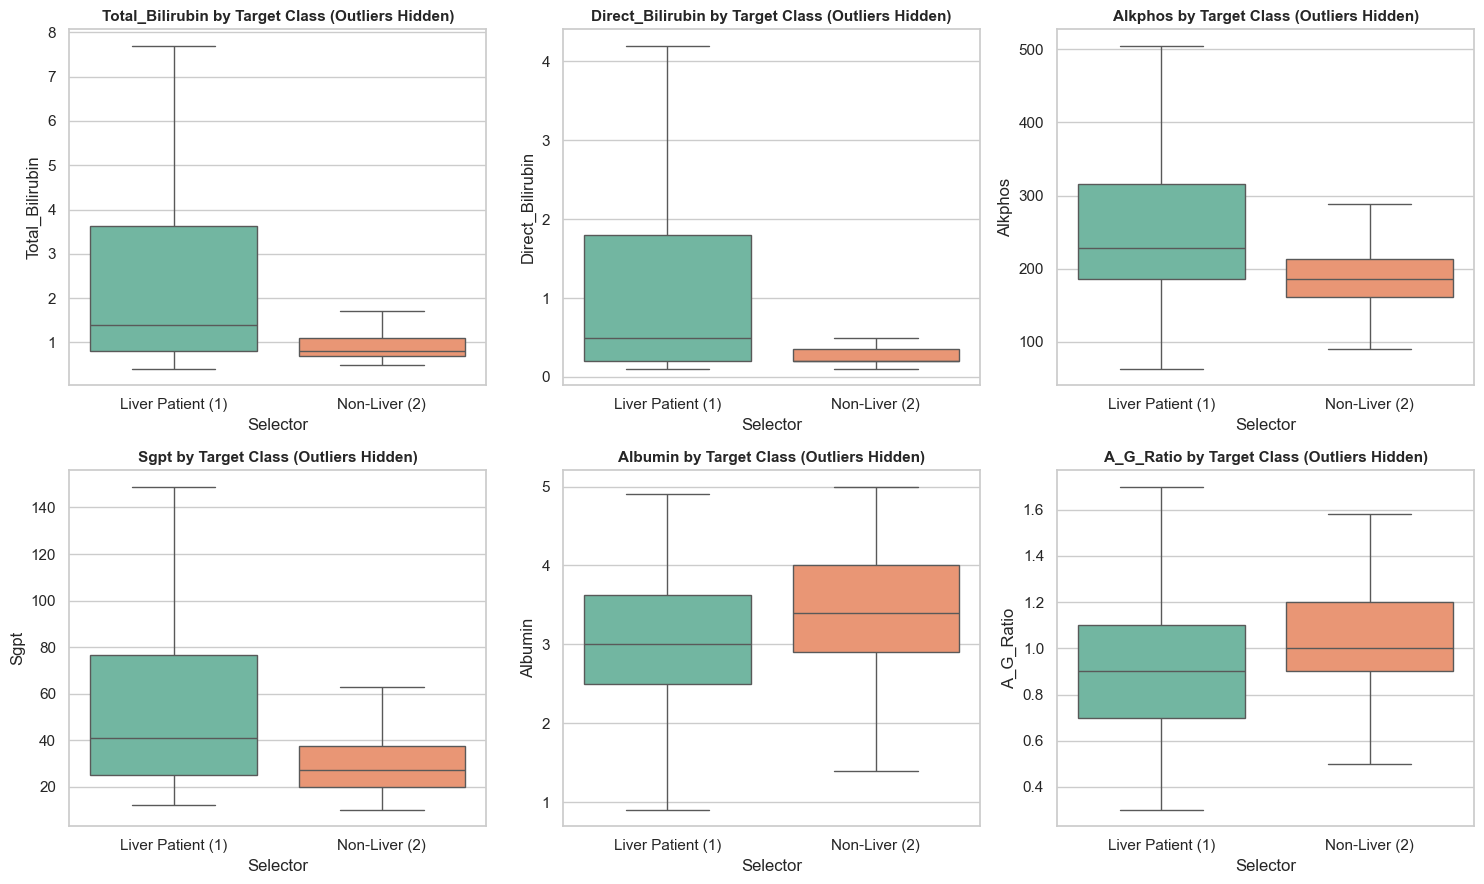

Comparative boxplots generated. Note: These visualizations show observed cohort associations and do not imply medical causation.


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
key_comp_features = ['Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Albumin', 'A_G_Ratio']

for ax, feat in zip(axes.flatten(), key_comp_features):
    sns.boxplot(data=df_raw, x='Selector', y=feat, palette='Set2', ax=ax, showfliers=False)
    ax.set_title(f'{feat} by Target Class (Outliers Hidden)', fontsize=11, fontweight='bold')
    ax.set_xticklabels(['Liver Patient (1)', 'Non-Liver (2)'])
    ax.set_xlabel('Selector')

plt.tight_layout()
plt.show()
print("Comparative boxplots generated. Note: These visualizations show observed cohort associations and do not imply medical causation.")

## Inspection Findings

- **Number of Rows**: 583 observations.
- **Number of Features**: 10 input features (9 numerical, 1 categorical).
- **Target Column**: `Selector`.
- **Target Class Distribution**:
  - Class `1` (Liver Disease Patient): 416 observations (71.36%)
  - Class `2` (Non-Liver Control): 167 observations (28.64%)
  - Class imbalance ratio: ~2.49 : 1.
- **Missing Values**:
  - `A_G_Ratio` (Albumin-to-Globulin Ratio) has **4 missing values** (0.69% of records).
  - All other 10 columns contain 0 missing values and 0 empty strings.
- **Duplicate Records**:
  - Exactly **13 duplicate rows** found (2.23% of records).
  - A total of 26 rows are involved in these duplicate pairs.
- **Categorical Features**:
  - `Gender`: 441 Males (75.64%) and 142 Females (24.36%). No invalid/unexpected strings.
- **Important Data-Quality Observations**:
  - Strong positive correlation between `Total_Bilirubin` and `Direct_Bilirubin` (r = 0.87).
  - Strong positive correlation between liver enzymes `Sgpt` (ALT) and `Sgot` (AST) (r = 0.79).
  - Strong positive correlation between `Total_Proteins` and `Albumin` (r = 0.78), and between `Albumin` and `A_G_Ratio` (r = 0.69).
- **Extreme-Value Observations**:
  - Several hepatic enzyme and biomarker distributions exhibit heavy right skew:
    - `Total_Bilirubin`: ranges up to 75.0 mg/dL (median = 1.0 mg/dL).
    - `Alkphos`: ranges up to 2110 U/L (median = 208 U/L).
    - `Sgpt`: ranges up to 2000 U/L (median = 35 U/L).
    - `Sgot`: ranges up to 4929 U/L (median = 42 U/L).
  - Extreme values correspond to acute hepatic flare-ups or obstructive jaundice rather than sensor glitches, requiring robust scaling strategies rather than unconsidered trimming.
- **Visible Dataset Limitations**:
  - Predominantly male cohort (75.64% male vs. 24.36% female).
  - Geographic/population specificity (collected from the North East of Andhra Pradesh, India). Findings cannot automatically be assumed to represent general global populations without calibration.

## Implications for Future Preprocessing and Modeling

Based strictly on findings from this exploratory inspection:

1. **Categorical Encoding for Gender**:
   - `Gender` is a binary categorical feature (`Male`/`Female`) and will need binary numeric encoding (e.g., Male=1, Female=0 or one-hot encoding) prior to model ingestion.

2. **Missing-Value Handling for `A_G_Ratio`**:
   - Exactly 4 observations lack `A_G_Ratio`.
   - Because `A_G_Ratio` is strongly correlated with `Albumin` (r = 0.69) and `Total_Proteins`, median imputation or predictive/formula-based imputation (`Albumin / (Total_Proteins - Albumin)`) can be evaluated without data loss.

3. **Feature Scaling for Sensitive Models**:
   - Features exhibit drastically different units and scales (e.g., `A_G_Ratio` from 0.3 to 2.8 vs. `Sgot` from 10 to 4929 U/L).
   - Distance-based and gradient-based models (e.g., Logistic Regression, SVM, KNN, Neural Networks) will require robust scaling (e.g., `RobustScaler` or `StandardScaler`), whereas tree-based ensembles (Random Forest, XGBoost) are scale-invariant.

4. **Class-Imbalance Handling and Metric Selection**:
   - Target ratio is ~2.49 : 1 (71.36% positive).
   - Standard accuracy will be misleading (a naive classifier predicting all patients as liver disease would achieve 71.36% accuracy).
   - Evaluation metrics must prioritize **PR-AUC, ROC-AUC, Recall/Sensitivity, Specificity, and F1-score**. Techniques such as class weighting (`class_weight='balanced'`) or SMOTE may be evaluated.

5. **Duplicate Handling Strategy**:
   - The 13 exact duplicate records must be carefully examined. If confirmed as duplicate entries of the same patient visit, deduplication prior to train/test splitting will be required to prevent data leakage.

6. **Train/Test Splitting & Leakage Prevention**:
   - Stratified train/test splitting (`StratifiedKFold`) must be employed to maintain the 71.36% / 28.64% class ratio across all folds.
   - All imputation parameters, scaling transforms, and encodings must be fitted strictly on training folds and only applied to validation/test folds to avoid data leakage.